###HLS_MODIS Spatial Comparison
This script will install GEE and extract Harmonised Landsat and Sentinel (HLS) data for all our global forest sites with observed mortality 2018 or later.
Comparing HLS (with fine spatial resolution of 30m point buffer) with the coarse resolution of MODIS (250m) will help us answer the question whether it is just MODIS data that cannot detect forest mortality or all satellite sourced veg indices (specifically NDVI).
Our hypothesis is that even the finer spatial resolution data will not detect lower % mortality sites due to the way ground observations are collected i.e. mortality of limited numbers of small trees vs canopy deterioration.

##Section 1 - Load libraries and EE

In [1]:
!pip install earthengine-api geemap pandas

import ee
import pandas as pd


ee.Authenticate()
ee.Initialize(project='ee1-jennyshep')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 37.0 MB/s eta 0:00:00


/usr/local/lib/python3.13/dist-packages/ee/data.py:335: UserWarning: Your project has exceeded the compute quota of its noncommercial tier and is currently in restricted mode.
  warnings.warn(


##Section 2 - Define site

In [53]:
site_geom = ee.Geometry.Point(
    [-3.9493, 50.4396]
).buffer(500)

print(
    site_geom.area().divide(10000).getInfo(),
    "ha"
)

77.60151583642813 ha


We are using harmonised Landsat-Sentinel (HLS) NDVI product (aggregated to 250m) as it provides 30m resolution, denser temporal coverage (ave 2 days revisit frequency) and is designed for long term consistency. This also enables longer time series (starts 2013, versus 2018 for sentinel). HLS is preferable to sentinel-only datasets for drought monitoring over multiple years.

A consistent moderate-resolution record from 2000-2025 is provided by MODIS which is being used for long term trend analysis. The HLS record provides higher-resolution observations from 2013 onwards for validation and mortality detection sensitivity comparison. Prior to SG smoothing and STL decomposition (to match the MODIS data) the HLS time series was resampled to a regular monthly time step. This will account for less frequent observations (16 day pre 2015 and 8 days pre 2018) earlier in the Landsat-Sentinel series. Once STL decomposed however, the trend component of the HLS data will be driven by vegetation dynamics vs the frequency of observation.

However, it is important to acknoweldge that the two systems use different instrument types resulting in absolute NDVI values and amplitudes. Hence the analysis will focus on NDVI difference/anomaly and trend analysis.

##We need to extract the HLS Landsat and HLS Sentinel datasets and merge them.
before applying cloud mask, calculating NDVI, creating monthly median composites, extracting mean NDVI,smooth with SG and perform STL decomposition. THis gives the densest HLS time series and creating monthly mediand NDVI composities mitigates the issue of varying observation density through time (i.e. 16 day revisit 2013-15, 8 days 2015-2017 etc.)

##Section 3 - HLS RGB function
Dont loop over 74 sites yet.
harz_mort is a good example for a pilot sites

In [54]:
def get_hls_rgb(year):

    return (
        ee.ImageCollection('NASA/HLS/HLSS30/v002')
        .filterBounds(site_geom)
        .filterDate(
            f'{year}-07-01',
            f'{year}-08-31'
        )
        .median()
        .clip(site_geom)
    )


MODIS equivalent

In [55]:
def get_modis_rgb(year):

    return (
        ee.ImageCollection('MODIS/061/MOD09A1')
        .filterBounds(site_geom)
        .filterDate(
            f'{year}-07-01',
            f'{year}-08-31'
        )
        .median()
        .clip(site_geom)
    )

##Section 4 - HLS NDVI function
One function only required!

In [56]:
def get_hls_ndvi(year):

    s30 = (
        ee.ImageCollection('NASA/HLS/HLSS30/v002')
        .filterBounds(site_geom)
        .filterDate(
            f'{year}-07-01',
            f'{year}-08-31'
        )
        .map(
            lambda img:
            img.normalizedDifference(
                ['B8A', 'B4']
            ).rename('NDVI')
        )
    )

    l30 = (
        ee.ImageCollection('NASA/HLS/HLSL30/v002')
        .filterBounds(site_geom)
        .filterDate(
            f'{year}-07-01',
            f'{year}-08-31'
        )
        .map(
            lambda img:
            img.normalizedDifference(
                ['B5', 'B4']
            ).rename('NDVI')
        )
    )

    return (
        s30
        .merge(l30)
        .median()
        .clip(site_geom)
    )

###MODIS equivalent

In [57]:
def get_modis_ndvi(year):

    return (
        ee.ImageCollection(
            'MODIS/061/MOD13Q1'
        )
        .filterBounds(site_geom)
        .filterDate(
            f'{year}-07-01',
            f'{year}-08-31'
        )
        .select('NDVI')
        .median()
        .multiply(0.0001)
        .clip(site_geom)
    )

##Section 5 - Create images
Change the before and after years depending on the observed mortality year for each site

In [58]:
hls_rgb_2017 = get_hls_rgb(2017)
hls_rgb_2025 = get_hls_rgb(2025)

modis_rgb_2017 = get_modis_rgb(2017)
modis_rgb_2025 = get_modis_rgb(2025)

hls_ndvi_2017 = get_hls_ndvi(2017)
hls_ndvi_2025 = get_hls_ndvi(2025)

modis_ndvi_2017 = get_modis_ndvi(2017)
modis_ndvi_2025 = get_modis_ndvi(2025)

###Change maps

In [59]:
hls_change = hls_ndvi_2025.subtract(
    hls_ndvi_2017
)

modis_change = modis_ndvi_2025.subtract(
    modis_ndvi_2017
)

###Visualisation settings

In [60]:
hls_rgb_vis = {
    'bands': ['B4', 'B3', 'B2'],
    'min': 100,
    'max': 1500,
    'gamma': 1.3
}

modis_rgb_vis = {
    'bands': [
        'sur_refl_b01',  # red
        'sur_refl_b04',  # green
        'sur_refl_b03'   # blue
    ],
    'min': 0,
    'max': 3000
}

ndvi_vis = {
    'min': 0,
    'max': 1,
    'palette': [
        '#8c510a',
        '#d8b365',
        '#f6e8c3',
        '#c7e9ad',
        '#78c679',
        '#238443'
    ]
}

change_vis = {
    'min': -0.4,
    'max': 0.4,
    'palette': [
        '#8b0000',
        '#ff9999',
        '#ffffff',
        '#99ff99',
        '#006400'
    ]
}


###Display maps

In [61]:
import geemap
Map = geemap.Map()

Map.centerObject(site_geom, 14)

Map.addLayer(
    hls_rgb_2017,
    hls_rgb_vis,
    'HLS RGB 2017'
)
Map.addLayer(
    hls_rgb_2025,
    hls_rgb_vis,
    'HLS RGB 2025'
)

Map.addLayer(
    modis_rgb_2017,
    modis_rgb_vis,
    'MODIS RGB 2017'
)
Map.addLayer(
    modis_rgb_2025,
    modis_rgb_vis,
    'MODIS RGB 2025'
)
Map.addLayer(
    hls_ndvi_2017,
    ndvi_vis,
    'HLS NDVI 2017'
)

Map.addLayer(
    hls_ndvi_2025,
    ndvi_vis,
    'HLS NDVI 2025'
)
Map.addLayer(
    modis_ndvi_2017,
    ndvi_vis,
    'MODIS NDVI 2017'
)
Map.addLayer(
    modis_ndvi_2025,
    ndvi_vis,
    'MODIS NDVI 2025'
)

Map.addLayer(
    hls_change,
    change_vis,
    'HLS ΔNDVI'
)

Map.addLayer(
    modis_change,
    change_vis,
    'MODIS ΔNDVI'
)

Map

Map(center=[50.439600512938995, -3.949299977643013], controls=(WidgetControl(options=['position', 'transparent…

###Export PNG
for any layer

In [62]:
url = hls_rgb_2017.getThumbURL({
    'region': site_geom.bounds(),
    'dimensions': 1000,
    'format': 'png',
    'bands': ['B4', 'B3', 'B2'],
    'min': 100,
    'max': 1500
})

print(url)

https://earthengine.googleapis.com/v1/projects/ee1-jennyshep/thumbnails/12413f574266f67ff037221c682cc957-6354f31a64c9bd58876217c854ffa66e:getPixels


###For HLS NDVI export

In [63]:
url = hls_ndvi_2017.getThumbURL({
    'region': site_geom.bounds(),
    'dimensions': 1000,
    'format': 'png',
    'min': 0,
    'max': 1,
    'palette': [
        '#8c510a',
        '#d8b365',
        '#f6e8c3',
        '#c7e9ad',
        '#78c679',
        '#238443'
    ]
})

print(url)

https://earthengine.googleapis.com/v1/projects/ee1-jennyshep/thumbnails/f587daef7e1227647477096c845bc1e2-1966b031727eb8d1cbadf489071e1b39:getPixels


In [64]:
url = hls_ndvi_2025.getThumbURL({
    'region': site_geom.bounds(),
    'dimensions': 1000,
    'format': 'png',
    'min': 0,
    'max': 1,
    'palette': [
        '#8c510a',
        '#d8b365',
        '#f6e8c3',
        '#c7e9ad',
        '#78c679',
        '#238443'
    ]
})

print(url)

https://earthengine.googleapis.com/v1/projects/ee1-jennyshep/thumbnails/29d862397d69de5a3ba2099a581ab0f4-f44554740aa8a69e413814167334e20c:getPixels


###HLS NDVI change export

In [65]:
url = hls_change.getThumbURL({
    'region': site_geom.bounds(),
    'dimensions': 1000,
    'format': 'png',
    'min': -0.4,
    'max': 0.4,
    'palette': [
        '#8b0000',
        '#ff9999',
        '#ffffff',
        '#99ff99',
        '#006400'
    ]
})

print(url)

https://earthengine.googleapis.com/v1/projects/ee1-jennyshep/thumbnails/4f7833b6c3f242840ddf8f35c400ae67-f89fa3f866eec4aa86948dde2d451292:getPixels


In [66]:
url = modis_change.getThumbURL({
    'region': site_geom.bounds(),
    'dimensions': 1000,
    'format': 'png',
    'min': -0.4,
    'max': 0.4,
    'palette': [
        '#8b0000',
        '#ff9999',
        '#ffffff',
        '#99ff99',
        '#006400'
    ]
})

print(url)

https://earthengine.googleapis.com/v1/projects/ee1-jennyshep/thumbnails/6b1cf7fee3b79604036acd12b4d77aeb-26216970e4b8eea96e86d65ebac0185c:getPixels


###MODIS NDVI export

In [67]:
url = modis_ndvi_2017.getThumbURL({
    'region': site_geom.bounds(),
    'dimensions': 1000,
    'format': 'png',
    'min': 0,
    'max': 1,
    'palette': [
        '#8c510a',
        '#d8b365',
        '#f6e8c3',
        '#c7e9ad',
        '#78c679',
        '#238443'
    ]
})

print(url)

https://earthengine.googleapis.com/v1/projects/ee1-jennyshep/thumbnails/32118a59084d0cfc8098c5d12aa8c251-939406733c3f67787a2b24518a4ba076:getPixels


In [68]:
url = modis_ndvi_2025.getThumbURL({
    'region': site_geom.bounds(),
    'dimensions': 1000,
    'format': 'png',
    'min': 0,
    'max': 1,
    'palette': [
        '#8c510a',
        '#d8b365',
        '#f6e8c3',
        '#c7e9ad',
        '#78c679',
        '#238443'
    ]
})

print(url)

https://earthengine.googleapis.com/v1/projects/ee1-jennyshep/thumbnails/ebcdd90ce39b90dea690d81b13317fb1-8ee014122f025387a8b46b0277e8e08a:getPixels


###Export to Drive

###Generic function - add this to notebook once

In [69]:
import requests

def save_png(image, filename, params):

    url = image.getThumbURL(params)

    r = requests.get(url)

    with open(filename, "wb") as f:
        f.write(r.content)

    print(f"Saved: {filename}")

then save each image with a single line as a PNG

In [70]:
save_png(
    modis_ndvi_2017,
    "modis_ndvi_2017.png",
    {
        'region': site_geom.bounds(),
        'dimensions': 800,
        'format': 'png',
        'min': 0,
        'max': 1,
        'palette': [
            '#8c510a',
            '#d8b365',
            '#f6e8c3',
            '#c7e9ad',
            '#78c679',
            '#238443'
        ]
    }
)

Saved: modis_ndvi_2017.png


In [71]:
save_png(
    modis_ndvi_2025,
    "modis_ndvi_2025.png",
    {
        'region': site_geom.bounds(),
        'dimensions': 800,
        'format': 'png',
        'min': 0,
        'max': 1,
        'palette': [
            '#8c510a',
            '#d8b365',
            '#f6e8c3',
            '#c7e9ad',
            '#78c679',
            '#238443'
        ]
    }
)

Saved: modis_ndvi_2025.png


In [72]:
save_png(
    hls_ndvi_2017,
    "hls_ndvi_2017.png",
    {
        'region': site_geom.bounds(),
        'dimensions': 800,
        'format': 'png',
        'min': 0,
        'max': 1,
        'palette': [
            '#8c510a',
            '#d8b365',
            '#f6e8c3',
            '#c7e9ad',
            '#78c679',
            '#238443'
        ]
    }
)

Saved: hls_ndvi_2017.png


In [73]:
save_png(
    hls_ndvi_2025,
    "hls_ndvi_2025.png",
    {
        'region': site_geom.bounds(),
        'dimensions': 800,
        'format': 'png',
        'min': 0,
        'max': 1,
        'palette': [
            '#8c510a',
            '#d8b365',
            '#f6e8c3',
            '#c7e9ad',
            '#78c679',
            '#238443'
        ]
    }
)

Saved: hls_ndvi_2025.png


In [74]:
save_png(
    hls_change,
    "hls_change.png",
    {
        'region': site_geom.bounds(),
        'dimensions': 800,
        'format': 'png',
        'min': -0.4,
        'max': 0.4,
        'palette': [
            '#8b0000',
            '#ff9999',
            '#ffffff',
            '#99ff99',
            '#006400'
        ]
    }
)

Saved: hls_change.png


In [75]:
save_png(
    modis_change,
    "modis_change.png",
    {
        'region': site_geom.bounds(),
        'dimensions': 800,
        'format': 'png',
        'min': -0.4,
        'max': 0.4,
        'palette': [
            '#8b0000',
            '#ff9999',
            '#ffffff',
            '#99ff99',
            '#006400'
        ]
    }
)

Saved: modis_change.png


###Six panel chart code

In [76]:
from PIL import Image

modis_ndvi_2017.png = Image.open("modis_ndvi_2017.png")
modis_ndvi_2025.png = Image.open("modis_ndvi_2025.png")

hls_ndvi_2017_png = Image.open("hls_ndvi_2017.png")
hls_ndvi_2025_png = Image.open("hls_ndvi_2025.png")

hls_change_png = Image.open("hls_change.png")
modis_change_png = Image.open("modis_change.png")

a 3x2 panel would be better to demonstrate the change and the difference in sensor

reduce the amount of labelling

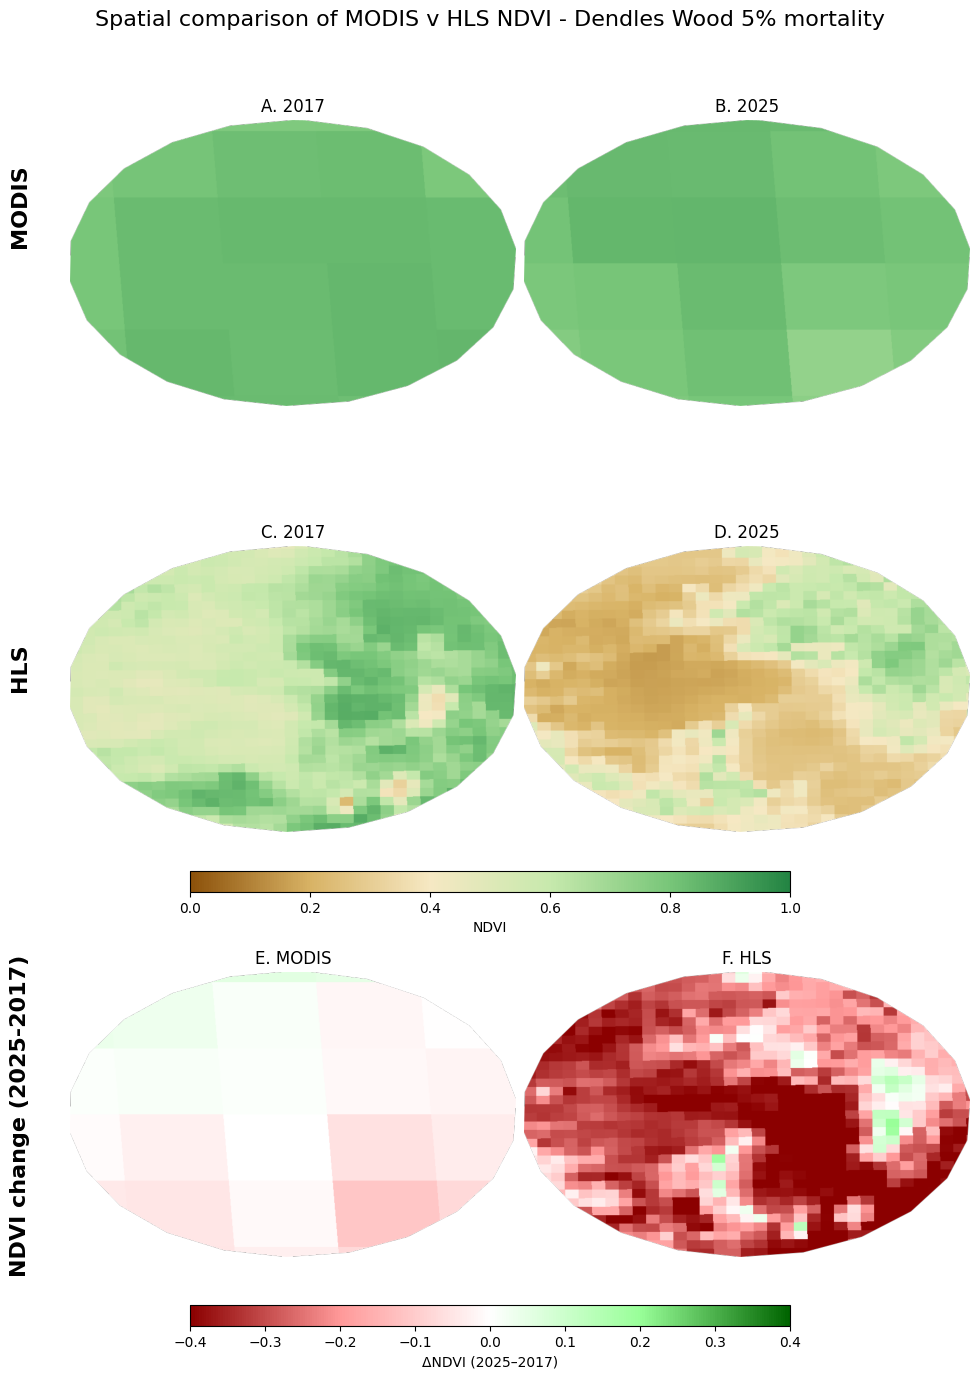

In [77]:
import matplotlib.pyplot as plt
from PIL import Image

# Load images

modis19 = Image.open("modis_ndvi_2017.png")
modis23 = Image.open("modis_ndvi_2025.png")

hls19 = Image.open("hls_ndvi_2017.png")
hls23 = Image.open("hls_ndvi_2025.png")

modis_change = Image.open("modis_change.png")
hls_change = Image.open("hls_change.png")

# Create figure

fig, axes = plt.subplots(
    3,
    2,
    figsize=(10, 14)
)

# Row 1 - MODIS

axes[0,0].imshow(modis19)
axes[0,0].set_title("A. 2017", fontsize=12)

axes[0,1].imshow(modis23)
axes[0,1].set_title("B. 2025", fontsize=12)

# Row 2 - HLS

axes[1,0].imshow(hls19)
axes[1,0].set_title("C. 2017", fontsize=12)

axes[1,1].imshow(hls23)
axes[1,1].set_title("D. 2025", fontsize=12)

# Row 3 - Change

axes[2,0].imshow(modis_change)
axes[2,0].set_title("E. MODIS", fontsize=12)

axes[2,1].imshow(hls_change)
axes[2,1].set_title("F. HLS", fontsize=12)

# Remove axes

for ax in axes.flatten():
    ax.axis("off")

# Row Labels

fig.text(
    0.02, 0.83,
    "MODIS",
    fontsize=16,
    fontweight="bold",
    rotation=90,
    va="center"
)

fig.text(
    0.02, 0.50,
    "HLS",
    fontsize=16,
    fontweight="bold",
    rotation=90,
    va="center"
)

fig.text(
    0.02, 0.18,
    "NDVI change (2025-2017)",
    fontsize=16,
    fontweight="bold",
    rotation=90,
    va="center"
)

# Figure title

fig.suptitle(
    "Spatial comparison of MODIS v HLS NDVI - Dendles Wood 5% mortality",
    fontsize=16,
    y=0.97
)

plt.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.93,
    bottom=0.04,
    wspace=0.02,
    hspace=0.08
)
import matplotlib as mpl

# NDVI colour scale
ndvi_cmap = mpl.colors.LinearSegmentedColormap.from_list(
    "ndvi",
    [
        "#8c510a",
        "#d8b365",
        "#f6e8c3",
        "#c7e9ad",
        "#78c679",
        "#238443"
    ]
)
ndvi_norm = mpl.colors.Normalize(vmin=0, vmax=1)

# Change colour scale
change_cmap = mpl.colors.LinearSegmentedColormap.from_list(
    "change",
    [
        "#8b0000",
        "#ff9999",
        "#ffffff",
        "#99ff99",
        "#006400"
    ]
)
change_norm = mpl.colors.Normalize(vmin=-0.4, vmax=0.4)

# NDVI colourbar

cax1 = fig.add_axes([0.20, 0.34, 0.60, 0.015])

cb1 = fig.colorbar(
    mpl.cm.ScalarMappable(
        norm=ndvi_norm,
        cmap=ndvi_cmap
    ),
    cax=cax1,
    orientation='horizontal'
)

cb1.set_label("NDVI")

# ΔNDVI colourbar

cax2 = fig.add_axes([0.20, 0.03, 0.60, 0.015])

cb2 = fig.colorbar(
    mpl.cm.ScalarMappable(
        norm=change_norm,
        cmap=change_cmap
    ),
    cax=cax2,
    orientation='horizontal'
)

cb2.set_label("ΔNDVI (2025–2017)")

plt.savefig(
    "MODIS_HLS_Dendles Wood.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [78]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [79]:
import os

os.makedirs(
    "/content/drive/MyDrive/HLS_MODIS_Figures",
    exist_ok=True
)

In [80]:
import shutil

for f in [
    "modis_ndvi_2017.png",
    "modis_ndvi_2025.png",
    "hls_ndvi_2017.png",
    "hls_ndvi_2025.png"
]:
    shutil.copy(
        f,
        "/content/drive/MyDrive/HLS_MODIS_Figures/" + f
    )

##NDVI Animation script
###This animation will illustrate the changes over time
comparing MODIS and HLS time series images

In [98]:
import ee
import requests
import imageio
import numpy as np

from PIL import Image, ImageDraw, ImageFont
from io import BytesIO

# --------------------------------------------------
# Earth Engine
# --------------------------------------------------

ee.Initialize(project='ee1-jennyshep')

# --------------------------------------------------
# Dendles Wood AOI
# Replace with exact Dendles Wood geometry
# --------------------------------------------------

aoi = ee.Geometry.Polygon([
    [-3.9515454, 50.4413780],
      [-3.9473243, 50.4413780],
      [-3.9472911, 50.4382704],
      [-3.9515454, 50.4382704],
      [-3.9515454, 50.4413780]]
)

# --------------------------------------------------
# Study period
# --------------------------------------------------

years = list(range(2016, 2025))
mortality_year = 2022


# --------------------------------------------------
# NDVI visualisation
# --------------------------------------------------

ndvi_vis = {
    'min': 0.2,
    'max': 0.9,
    'palette': [
        '#8c510a',
        '#d8b365',
        '#f6e8c3',
        '#c7eae5',
        '#5ab4ac',
        '#01665e'
    ]
}

#--------------------------------------------------
#Cloud mask
#--------------------------------------------------
def mask_hls(img):

    fmask = img.select('Fmask')

    clear = fmask.eq(0)

    return img.updateMask(clear)

# --------------------------------------------------
# MODIS NDVI
# --------------------------------------------------

def get_modis_ndvi(year):

    start = f'{year}-06-01'
    end = f'{year}-08-31'

    ndvi = (
        ee.ImageCollection('MODIS/061/MOD13Q1')
        .filterDate(start, end)
        .select('NDVI')
        .median()
        .multiply(0.0001)
    )

    return ndvi.clip(aoi)

# --------------------------------------------------
# HLS NDVI - Sentinel only
# --------------------------------------------------
def get_hls_ndvi(year):

    start = f"{year}-06-01"
    end   = f"{year}-08-31"

    ndvi = (
        ee.ImageCollection("NASA/HLS/HLSS30/v002")
        .filterBounds(aoi)
        .filterDate(start,end)
        .map(
            lambda img:
            img.normalizedDifference(
                ['B8A','B4']
            ).rename('NDVI')
        )
        .reduce(
            ee.Reducer.percentile([75])
        )
        .rename('NDVI')
    )

    return ndvi.clip(aoi)



then run

In [99]:
test = get_hls_ndvi(2019)

print(
    test.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=aoi,
        scale=30,
        maxPixels=1e13
    ).getInfo()
)

{'NDVI': 0.8605473488229972}


###Calculate both NDVI trajectories

In [100]:
years = list(range(2016, 2025))

modis_means = []
hls_means = []

for year in years:

    modis = get_modis_ndvi(year)

    hls = get_hls_ndvi(year)

    mod_val = (
        modis.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=aoi,
            scale=250,
            maxPixels=1e13
        )
        .get('NDVI')
        .getInfo()
    )

    hls_val = (
        hls.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=aoi,
            scale=30,
            maxPixels=1e13
        )
        .get('NDVI')
        .getInfo()
    )

    modis_means.append(mod_val)
    hls_means.append(hls_val)

    print(year, mod_val, hls_val)


2016 0.8701128787878788 0.8028898676189077
2017 0.8428561363636362 0.7333907071885943
2018 0.8427470454545455 0.8239966089911879
2019 0.853423712121212 0.8605473488229972
2020 0.863340984848485 0.8131938503295992
2021 0.8692134848484848 0.8311947650213014
2022 0.8351664393939394 0.8523287074162362
2023 0.845573106060606 0.8268481275089961
2024 0.874032803030303 0.6320094862955455


In [101]:
for i, y in enumerate(years):
    print(i, y)

print()

for i, m in enumerate(modis_means):
    print(i, m)

0 2016
1 2017
2 2018
3 2019
4 2020
5 2021
6 2022
7 2023
8 2024

0 0.8701128787878788
1 0.8428561363636362
2 0.8427470454545455
3 0.853423712121212
4 0.863340984848485
5 0.8692134848484848
6 0.8351664393939394
7 0.845573106060606
8 0.874032803030303


###Then plot the trajectories

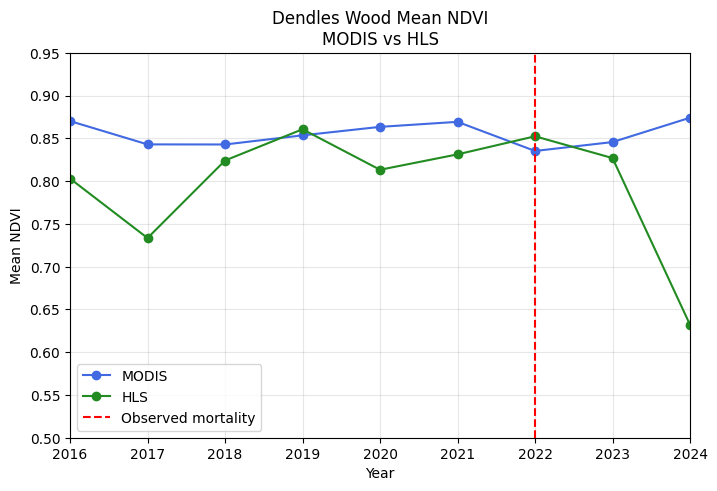

In [102]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    years,
    modis_means,
    '-o',
    label='MODIS',
    color='royalblue'
)

plt.plot(
    years,
    hls_means,
    '-o',
    label='HLS',
    color='forestgreen'
)

plt.axvline(
    2022,
    color='red',
    linestyle='--',
    label='Observed mortality'
)

plt.ylabel('Mean NDVI')
plt.xlabel('Year')

plt.title(
    'Dendles Wood Mean NDVI\nMODIS vs HLS'
)
# Set common axis limits
plt.ylim(0.5, 0.95)
plt.xlim(2016, 2024)

plt.legend()

plt.grid(alpha=0.3)

plt.savefig(
    "MODIS_HLS_mean_NDVI_Dendles Wood.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

###Create animation frames

In [103]:
import matplotlib.pyplot as plt
import imageio.v2 as imageio
import requests

from PIL import Image
from io import BytesIO

frames = []

for i, year in enumerate(years):

    print(f"Creating frame {year}")

    modis = get_modis_ndvi(year)
    hls = get_hls_ndvi(year)

    # ----------------------
    # download map images
    # ----------------------

    mod_url = modis.visualize(**ndvi_vis).getThumbURL({
        'region': aoi.bounds(),
        'dimensions': 600
    })

    hls_url = hls.visualize(**ndvi_vis).getThumbURL({
        'region': aoi.bounds(),
        'dimensions': 600
    })

    mod_img = Image.open(
        BytesIO(
            requests.get(mod_url).content
        )
    )

    hls_img = Image.open(
        BytesIO(
            requests.get(hls_url).content
        )
    )

    # ----------------------
    # make figure
    # ----------------------

    fig = plt.figure(
        figsize=(12,8)
    )

    # MODIS map

    ax1 = plt.subplot2grid(
        (2,2),
        (0,0)
    )

    ax1.imshow(mod_img)

    ax1.set_title(
        f"MODIS NDVI\n{year}"
    )

    ax1.axis('off')

    # HLS map

    ax2 = plt.subplot2grid(
        (2,2),
        (0,1)
    )

    ax2.imshow(hls_img)

    ax2.set_title(
        f"HLS NDVI\n{year}"
    )

    ax2.axis('off')

    # trajectory

    ax3 = plt.subplot2grid(
        (2,2),
        (1,0),
        colspan=2
    )

    ax3.plot(
        years,
        modis_means,
        '-o',
        color='royalblue',
        label='MODIS'
    )

    ax3.plot(
        years,
        hls_means,
        '-o',
        color='forestgreen',
        label='HLS'
    )

    ax3.axvline(
        mortality_year,
        color='red',
        linestyle='--',
        label='Observed mortality'
    )

    ax3.scatter(
        years[i],
        modis_means[i],
        s=150,
        color='royalblue',
        zorder=10
    )

    ax3.scatter(
        years[i],
        hls_means[i],
        s=150,
        color='forestgreen',
        zorder=10
    )

    ax3.set_ylabel('Mean NDVI')

    ax3.set_xlabel('Year')

    ax3.set_title(
        'Marston_Thrift: MODIS vs HLS NDVI'
    )

    ax3.legend()

    ax3.grid(
        alpha=0.3
    )

    plt.tight_layout()

    frame_file = f'frame_{year}.png'

    plt.savefig(
        frame_file,
        dpi=150
    )

    plt.close()

    frames.append(
        imageio.imread(frame_file)
    )

Creating frame 2016
Creating frame 2017
Creating frame 2018
Creating frame 2019
Creating frame 2020
Creating frame 2021
Creating frame 2022
Creating frame 2023
Creating frame 2024


###Build the GIF

In [104]:
imageio.mimsave(
    'Dendles_Wood_MODIS_HLS_NDVI.gif',
    frames,
    duration=1.2,
    loop=0
)

print("GIF created successfully")

GIF created successfully


###Save/export GIF


In [106]:
imageio.mimsave(
    'Dendles_Wood_MODIS_vs_HLS_NDVI.gif',
    frames,
    duration=1.2
)

print("GIF saved")

GIF saved


###Save/export MP4
Many journals and conference platforms prefer MP4 over GIF

In [107]:
imageio.mimsave(
    'Dendles_Wood_MODIS_HLS_NDVI.mp4',
    frames,
    fps=1
)
print("MP4 saved")

MP4 saved


##We are now wanting to run MODIS v HLS comparisons
This will include auditing the 'sentinel_sites_v2' dataset (only including those sites with full data series for MODIS and HLS); plotting trajectories, computing and summarising stats and possibly animations for all sentinel sites (74)

###First we run the data audit
Create a buffer around each point (500m)
Check HLS observations (2016-2025)
Check MODIS observations
Flag sites with sufficient data

In [38]:
import pandas as pd
import ee

sites = pd.read_csv(
    '/content/drive/MyDrive/sentinel_sites_v2.csv'
)

audit = []

for _, row in sites.iterrows():

    site = row['plot_id']

    lat = row['lat']
    lon = row['long']

    aoi = (
        ee.Geometry.Point([lon, lat])
        .buffer(500)
    )

    hls_n = (
        ee.ImageCollection(
            'NASA/HLS/HLSS30/v002'
        )
        .filterBounds(aoi)
        .filterDate(
            '2016-01-01',
            '2024-12-31'
        )
        .size()
        .getInfo()
    )

    modis_n = (
        ee.ImageCollection(
            'MODIS/061/MOD13Q1'
        )
        .filterBounds(aoi)
        .filterDate(
            '2016-01-01',
            '2024-12-31'
        )
        .size()
        .getInfo()
    )

    audit.append([
        site,
        hls_n,
        modis_n
    ])

audit_df = pd.DataFrame(
    audit,
    columns=[
        'site',
        'hls_images',
        'modis_images'
    ]
)

audit_df.to_csv(
    'site_audit.csv',
    index=False
)

###Compute decline metrics

In [39]:
import numpy as np
import pandas as pd

def compute_metrics(years, values, mortality_year):

    if pd.isna(mortality_year):
        return None

    values = np.array(values)

    pre = values[
        np.array(years) < mortality_year
    ]

    post = values[
        np.array(years) >= mortality_year
    ]

    if len(pre) == 0:
        return None

    if len(post) == 0:
        return None

    pre_mean = np.mean(pre)

    post_min = np.min(post)

    decline_pct = (
        (post_min - pre_mean)
        / pre_mean
    ) * 100

    recovery_threshold = 0.95 * pre_mean

    recovery_year = None

    for y, v in zip(years, values):

        if (
            y > mortality_year and
            v >= recovery_threshold
        ):

            recovery_year = y
            break

    if recovery_year is None:

        years_to_recovery = None

    else:

        years_to_recovery = (
            recovery_year - mortality_year
        )

    return {
        'pre_mean': pre_mean,
        'post_min': post_min,
        'decline_pct': decline_pct,
        'recovery_year': recovery_year,
        'years_to_recovery': years_to_recovery
    }

###NDVI extraction function
using the same approach that worked for Harz

In [40]:
def annual_mean_ndvi(image,
                     aoi,
                     scale):

    val = (
        image.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=aoi,
            scale=scale,
            maxPixels=1e13
        )
        .get('NDVI')
        .getInfo()
    )

    return val

###Run the main loop for all 74 sites

In [41]:
import pandas as pd

sites = pd.read_csv(
    '/content/drive/MyDrive/sentinel_sites_v2.csv'
)

years = list(range(2016, 2025))

results = []

###Process every site

In [42]:
for idx, row in sites.iterrows():

    site = row['plot_id']

    print(f"\nProcessing: {site}")

    try:

        lat = row['lat']
        lon = row['long']

        mort_year = row['mort_year']
        mort_pct = row['mortality_pct']

        aoi = ee.Geometry.Point([lon, lat]).buffer(500)

        modis_means = []
        hls_means = []

        for year in years:

            modis = get_modis_ndvi(year)
            hls = get_hls_ndvi(year)

            mod_val = annual_mean_ndvi(
                modis,
                aoi,
                250
            )

            hls_val = annual_mean_ndvi(
                hls,
                aoi,
                30
            )

            modis_means.append(mod_val)
            hls_means.append(hls_val)

        mod_metrics = compute_metrics(
            years,
            modis_means,
            mort_year
        )

        hls_metrics = compute_metrics(
            years,
            hls_means,
            mort_year
        )


        results.append({

    'plot_id': site,

    'mort_year': mort_year,

    'mort_pct': mort_pct,

    'modis_pre_mean':
        mod_metrics['pre_mean'],

    'modis_post_min':
        mod_metrics['post_min'],

    'modis_decline_pct':
        mod_metrics['decline_pct'],

    'modis_recovery_year':
        mod_metrics['recovery_year'],

    'modis_years_to_recovery':
        mod_metrics['years_to_recovery'],

    'hls_pre_mean':
        hls_metrics['pre_mean'],

    'hls_post_min':
        hls_metrics['post_min'],

    'hls_decline_pct':
        hls_metrics['decline_pct'],

    'hls_recovery_year':
        hls_metrics['recovery_year'],

    'hls_years_to_recovery':
        hls_metrics['years_to_recovery']
})

        print("SUCCESS")

    except Exception as e:

        print("FAILED")
        print(e)


Processing: Wald_mort
SUCCESS

Processing: Wald_control
SUCCESS

Processing: Harz_mort
SUCCESS

Processing: Harz_control
SUCCESS

Processing: Bav_mort
SUCCESS

Processing: Bav_control
SUCCESS

Processing: NHC
SUCCESS

Processing: NRC
SUCCESS

Processing: NHG
SUCCESS

Processing: NML
SUCCESS

Processing: CSC
SUCCESS

Processing: CPC
SUCCESS

Processing: CCS
SUCCESS

Processing: CBP
SUCCESS

Processing: SPA
SUCCESS

Processing: SBM
SUCCESS

Processing: SKC
SUCCESS

Processing: SHC
SUCCESS

Processing: Blattenberg
SUCCESS

Processing: Grosszinggibrunn
SUCCESS

Processing: Rootriss
SUCCESS

Processing: Tueliboden
SUCCESS

Processing: Usserholz
SUCCESS

Processing: Vogtacher
SUCCESS

Processing: Buckholt Wood
SUCCESS

Processing: Clairinshe
SUCCESS

Processing: Craigellachie
SUCCESS

Processing: Dendles Wood
SUCCESS

Processing: Denny Woods
SUCCESS

Processing: Glen Tanar
SUCCESS

Processing: Lady Park
SUCCESS

Processing: Langley Woods
SUCCESS

Processing: Monks Wood
SUCCESS

Processing: 

###Save outputs - summary table

In [43]:
results.append({

        'plot_id': site,

        'mort_year': mort_year,

        'mort_pct': mort_pct,

        'modis_pre_mean':
            mod_metrics['pre_mean'],

        'modis_post_min':
            mod_metrics['post_min'],

        'modis_decline_pct':
            mod_metrics['decline_pct'],

        'modis_recovery_year':
            mod_metrics['recovery_year'],

        'hls_pre_mean':
            hls_metrics['pre_mean'],

        'hls_post_min':
            hls_metrics['post_min'],

        'hls_decline_pct':
            hls_metrics['decline_pct'],

        'hls_recovery_year':
            hls_metrics['recovery_year']
    })

###Create trajectory plot for each site
Create an output folder first

In [44]:
import os

os.makedirs(
    'trajectories',
    exist_ok=True
)

In [45]:
print(
    site,
    mod_metrics['decline_pct'],
    hls_metrics['decline_pct']
)

Crete3 -11.655088665016397 -11.544140376894815


Load the metrics

In [46]:
#------------------------------
#load metrics
#------------------------------
metrics = pd.read_csv(
    '/content/drive/MyDrive/all_site_metrics_v2_FINAL.csv'
)

Then inside the site loop, adding a summary box

In [47]:
import os
import ee
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# Load data
# --------------------------------------------------

sites = pd.read_csv(
    '/content/drive/MyDrive/sentinel_sites_v2.csv'
)

metrics = pd.read_csv(
    '/content/drive/MyDrive/all_site_metrics_v2_FINAL.csv'
)

# Remove accidental whitespace

sites['plot_id'] = (
    sites['plot_id']
    .astype(str)
    .str.strip()
)

metrics['plot_id'] = (
    metrics['plot_id']
    .astype(str)
    .str.strip()
)

# --------------------------------------------------
# Output folder
# --------------------------------------------------

os.makedirs(
    'trajectories',
    exist_ok=True
)

# --------------------------------------------------
# Analysis years
# --------------------------------------------------

years = list(range(2016, 2025))

# --------------------------------------------------
# Loop through sites
# --------------------------------------------------

for idx, row in sites.iterrows():

    site = row['plot_id']

    lat = row['lat']
    lon = row['long']

    mort_year = row['mort_year']

    print(
        f'Creating trajectory: {site}'
    )

    # --------------------------------------------------
    # Find matching metrics row
    # --------------------------------------------------

    match = metrics[
        metrics['plot_id'] == site
    ]

    if len(match) == 0:

        print(
            f'No metrics found: {site}'
        )

        continue

    site_metrics = match.iloc[0]

    # --------------------------------------------------
    # Create AOI
    # --------------------------------------------------

    aoi = (
        ee.Geometry.Point(
            [lon, lat]
        )
        .buffer(500)
    )

    # --------------------------------------------------
    # Annual trajectories
    # --------------------------------------------------

    modis_means = []
    hls_means = []

    for year in years:

        modis = get_modis_ndvi(year)

        hls = get_hls_ndvi(year)

        mod_val = annual_mean_ndvi(
            modis,
            aoi,
            250
        )

        hls_val = annual_mean_ndvi(
            hls,
            aoi,
            30
        )

        modis_means.append(
            mod_val
        )

        hls_means.append(
            hls_val
        )

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------

    plt.figure(
        figsize=(8,5)
    )

    plt.plot(
        years,
        modis_means,
        '-o',
        color='royalblue',
        linewidth=2,
        label='MODIS'
    )

    plt.plot(
        years,
        hls_means,
        '-o',
        color='forestgreen',
        linewidth=2,
        label='HLS'
    )

    plt.axvline(
        mort_year,
        color='red',
        linestyle='--',
        linewidth=1,
        label='Mortality Year'
    )

    # --------------------------------------------------
    # Title with metrics
    # --------------------------------------------------

    plt.title(
        f"{site}\n"
        f"Mortality={row['mortality_pct']:.1f}% | "
        f"MODIS decline={site_metrics['modis_decline_pct']:.1f}% | "
        f"HLS decline={site_metrics['hls_decline_pct']:.1f}%"
    )

    plt.xlabel(
        'Year'
    )

    plt.ylabel(
        'Mean NDVI'
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend(
        loc='best'
    )
#-------------------------------------------------------
# Use consistent x and y axis scales
#-------------------------------------------------------
    plt.ylim(
    0.25,
    0.95
    )

    plt.xlim(
    2015.5,
    2024.5
    )

    plt.tight_layout()

    # --------------------------------------------------
    # Save
    # --------------------------------------------------

    outfile = (
        f'trajectories/{site}.png'
    )

    plt.savefig(
        outfile,
        dpi=300,
        bbox_inches='tight'
    )

    plt.close()

print(
    'All trajectory plots completed'
)

Creating trajectory: Wald_mort
Creating trajectory: Wald_control
Creating trajectory: Harz_mort
Creating trajectory: Harz_control
Creating trajectory: Bav_mort
Creating trajectory: Bav_control
Creating trajectory: NHC
No metrics found: NHC
Creating trajectory: NRC
No metrics found: NRC
Creating trajectory: NHG
No metrics found: NHG
Creating trajectory: NML
No metrics found: NML
Creating trajectory: CSC
No metrics found: CSC
Creating trajectory: CPC
No metrics found: CPC
Creating trajectory: CCS
No metrics found: CCS
Creating trajectory: CBP
No metrics found: CBP
Creating trajectory: SPA
No metrics found: SPA
Creating trajectory: SBM
No metrics found: SBM
Creating trajectory: SKC
No metrics found: SKC
Creating trajectory: SHC
No metrics found: SHC
Creating trajectory: Blattenberg
Creating trajectory: Grosszinggibrunn
Creating trajectory: Rootriss
Creating trajectory: Tueliboden
Creating trajectory: Usserholz
Creating trajectory: Vogtacher
Creating trajectory: Buckholt Wood
Creating traj

In [48]:
mod_metrics = compute_metrics(
    years,
    modis_means,
    mort_year
)

print(mod_metrics)

{'pre_mean': np.float64(0.3515833559857473), 'post_min': np.float64(0.3106060041141682), 'decline_pct': np.float64(-11.655088665016397), 'recovery_year': None, 'years_to_recovery': None}


In [64]:
from pathlib import Path

out_dir = Path("/content/drive/MyDrive/trajectories")
out_dir.mkdir(parents=True, exist_ok=True)

In [66]:
import matplotlib.pyplot as plt

plt.figure(
    figsize=(8,5)
)

plt.plot(
    years,
    modis_means,
    '-o',
    color='royalblue',
    label='MODIS'
)

plt.plot(
    years,
    hls_means,
    '-o',
    color='forestgreen',
    label='HLS'
)

plt.axvline(
    mort_year,
    color='red',
    linestyle='--',
    label='Mortality'
)

plt.title(site)

plt.ylabel('Mean NDVI')

plt.xlabel('Year')

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

print(f"Saving figure: {site}")

plt.savefig(
    out_dir / f"{site}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

import os

print(f"Files saved: {len(os.listdir(out_dir))}")
print(os.listdir(out_dir)[:5])

Saving figure: Crete3
Files saved: 1
['Crete3.png']


###Export master metrics table
after the loop

In [50]:
results_df = pd.DataFrame(results)

results_df.to_csv(
    'all_site_metrics.csv',
    index=False
)

print(
    'Saved all_site_metrics.csv'
)

Saved all_site_metrics.csv


##Results analysis

###1. Load the data

In [88]:
import pandas as pd
import numpy as np

df = pd.read_csv("/content/drive/MyDrive/all_site_metrics (4).csv")

print(df.shape)
df.head()

(75, 13)


,plot_id,mort_year,mort_pct,modis_pre_mean,modis_post_min,modis_decline_pct,modis_recovery_year,modis_years_to_recovery,hls_pre_mean,hls_post_min,hls_decline_pct,hls_recovery_year,hls_years_to_recovery
0,Wald_mort,2020,63.0,0.827772,0.777733,-6.045010,2024.0,4.0,0.839881,0.764204,-9.010419,2023.0,3.0
1,Wald_control,2020,10.0,0.808356,0.782904,-3.148588,2021.0,1.0,0.836102,0.815176,-2.502824,2021.0,1.0
2,Harz_mort,2019,80.0,0.853973,0.506657,-40.670543,NaN,NaN,0.848945,0.558385,-34.226007,NaN,NaN
3,Harz_control,2019,0.0,0.849212,0.718524,-15.389398,NaN,NaN,0.857912,0.703490,-17.999719,NaN,NaN
4,Bav_mort,2020,87.0,0.838864,0.747426,-10.900178,2021.0,1.0,0.830775,0.755605,-9.048132,NaN,NaN


check common names

In [89]:
df.columns.tolist()

['plot_id',
 'mort_year',
 'mort_pct',
 'modis_pre_mean',
 'modis_post_min',
 'modis_decline_pct',
 'modis_recovery_year',
 'modis_years_to_recovery',
 'hls_pre_mean',
 'hls_post_min',
 'hls_decline_pct',
 'hls_recovery_year',
 'hls_years_to_recovery']

###2. Summary statistics table
This represents the basic results for the paper

In [90]:
metrics = [
    'mort_pct',
    'modis_decline_pct',
    'hls_decline_pct',
    'modis_years_to_recovery',
    'hls_years_to_recovery'
]

summary = df[metrics].describe().round(2)

summary

,mort_pct,modis_decline_pct,hls_decline_pct,modis_years_to_recovery,hls_years_to_recovery
count,75.00,75.00,75.00,71.00,69.00
mean,25.55,-6.29,-4.67,1.20,1.06
std,21.09,6.74,11.01,0.58,0.29
min,0.00,-40.67,-51.35,1.00,1.00
25%,10.75,-10.01,-8.92,1.00,1.00
50%,15.00,-3.63,-3.08,1.00,1.00
75%,46.50,-1.80,-0.53,1.00,1.00
max,87.00,3.58,33.08,4.00,3.00


save

In [91]:
summary.to_csv(
    "/content/drive/MyDrive/results_summary_stats.csv"
)

###3. MODIS vs HLS decline
A very important figure

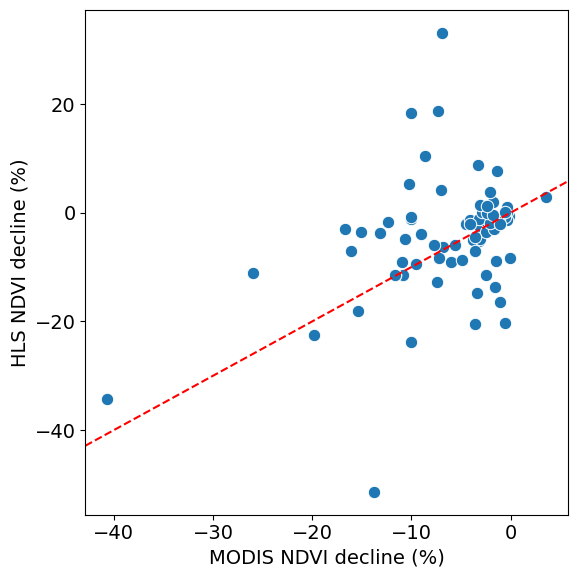

In [92]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,6))

sns.scatterplot(
    data=df,
    x='modis_decline_pct',
    y='hls_decline_pct',
    s=80
)

plt.axline(
    (0,0),
    slope=1,
    color='red',
    linestyle='--'
)

plt.rcParams["font.size"] = 14

plt.xlabel('MODIS NDVI decline (%)')
plt.ylabel('HLS NDVI decline (%)')

plt.tight_layout()

plt.savefig(
    '/content/drive/MyDrive/Figure1_MODIS_HLS_decline.png',
    dpi=300
)

plt.show()

 MODIS and HLS estimates of NDVI decline showed a positive association across sites (points near the 1:1 dotted line), indicating that both sensors detected comparable patterns of vegetation disturbance. However, substantial scatter around the line indicate important differences in magnitude of disturbance estimates at individual sites. These points likely reflect differences in spatial resolution;  HLS (30 m) sensor data is sensitive to finer-scale canopy mortality and different processes of recovery. This detail is averaged out within the coarser MODIS footprint (~250 m). The points furthest from the 1:1 line represent sites with severe mortality or rapid post-disturbance vegetation response. These highlight how  spatial heterogeneity can impact on accuracy of remotely-sensed forest condition estimates condition.

Calculate Spearmans rho correlation coefficient

In [102]:
from scipy.stats import spearmanr

rho, p = spearmanr(
    df['mort_pct'],
    df['modis_decline_pct'],
    nan_policy='omit'
)

print(f"Spearman rho = {rho:.3f}")
print(f"p-value = {p:.4f}")

Spearman rho = -0.176
p-value = 0.1309


and Pearson coefficient

In [103]:
from scipy.stats import pearsonr

r, p = pearsonr(
    df['mort_pct'],
    df['modis_decline_pct']
)

print(f"Pearson r = {r:.3f}")
print(f"p-value = {p:.4f}")

Pearson r = -0.286
p-value = 0.0129


###4. Mortality versus NDVI decline
An important ecological relationship.

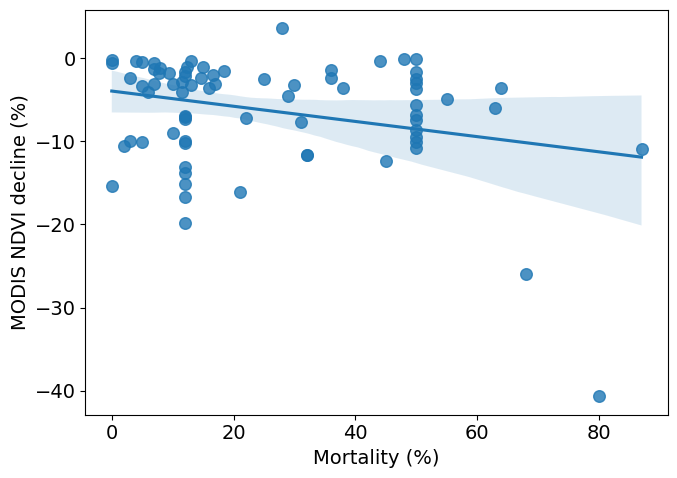

In [93]:
plt.figure(figsize=(7,5))

sns.regplot(
    data=df,
    x='mort_pct',
    y='modis_decline_pct',
    scatter_kws={'s':70}
)

plt.xlabel('Mortality (%)')
plt.ylabel('MODIS NDVI decline (%)')

plt.tight_layout()

plt.savefig(
    '/content/drive/MyDrive/Figure2_Mortality_vs_MODIS.png',
    dpi=300
)

plt.show()

Then HLS

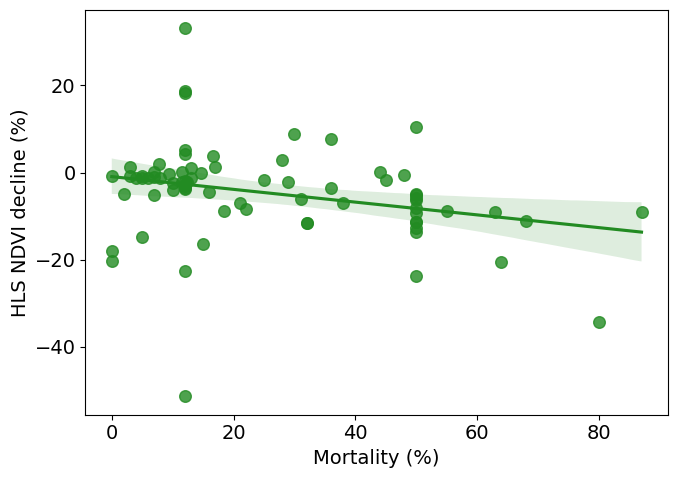

In [94]:
plt.figure(figsize=(7,5))

sns.regplot(
    data=df,
    x='mort_pct',
    y='hls_decline_pct',
    scatter_kws={'s':70},
    color='forestgreen'
)

plt.xlabel('Mortality (%)')
plt.ylabel('HLS NDVI decline (%)')

plt.tight_layout()

plt.savefig(
    '/content/drive/MyDrive/Figure3_Mortality_vs_HLS.png',
    dpi=300
)

###Correlation analysis
Quantify the relationships

In [95]:
from scipy.stats import spearmanr

corr_modis, p_modis = spearmanr(
    df['mort_pct'],
    df['modis_decline_pct']
)

corr_hls, p_hls = spearmanr(
    df['mort_pct'],
    df['hls_decline_pct']
)

print(
    f"MODIS: rho={corr_modis:.2f}, p={p_modis:.4f}"
)

print(
    f"HLS: rho={corr_hls:.2f}, p={p_hls:.4f}"
)

MODIS: rho=-0.18, p=0.1309
HLS: rho=-0.35, p=0.0023


Mortality percentage was positively correlated with NDVI decline, indicating that more severe mortality events resulted in greater vegetation loss. This was statistically significant relationship for HLS data (p=0.0023)?

###6. Recovery time comparison
This directly compares sensor-derived recovery estimates.

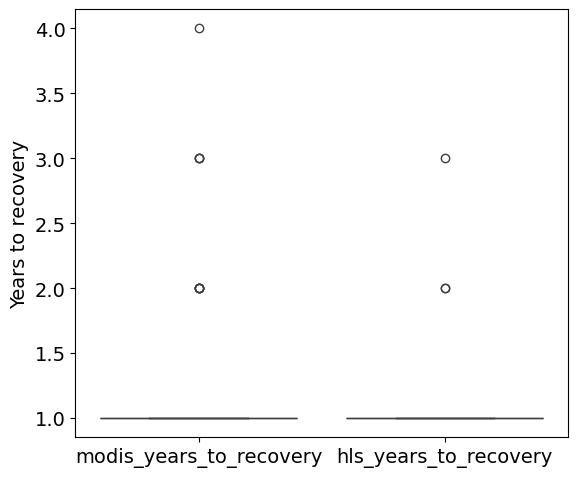

In [96]:
recovery = df[
    [
        'modis_years_to_recovery',
        'hls_years_to_recovery'
    ]
]

plt.figure(figsize=(6,5))

sns.boxplot(data=recovery)

plt.ylabel('Years to recovery')

plt.tight_layout()

plt.savefig(
    '/content/drive/MyDrive/Figure4_Recovery_times.png',
    dpi=300
)

plt.show()

###7. Mortality classes
A very clean publication figure.

In [97]:
df['mort_class'] = pd.cut(
    df['mort_pct'],
    bins=[0,10,25,50,75,100],
    labels=[
        '0-10',
        '10-25',
        '25-50',
        '50-75',
        '75-100'
    ]
)

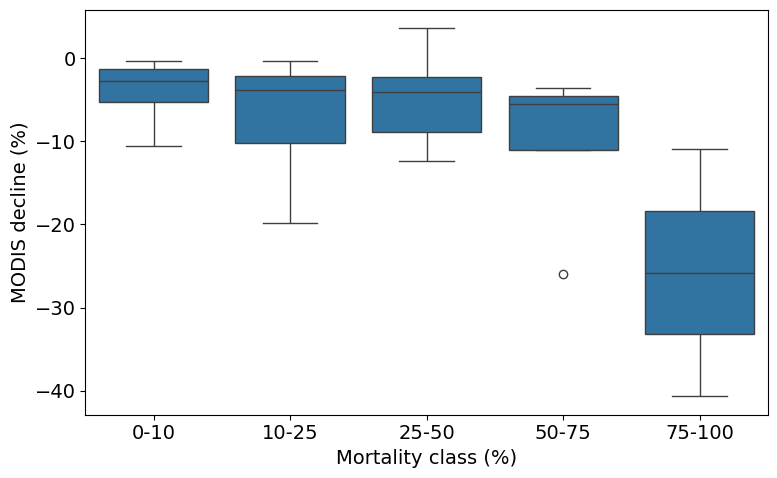

In [99]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='mort_class',
    y='modis_decline_pct'
)

plt.xlabel('Mortality class (%)')
plt.ylabel('MODIS decline (%)')

plt.tight_layout()

plt.savefig(
    '/content/drive/MyDrive/Figure5_Mortality_classes.png',
    dpi=300
)

plt.show()

###8. Correlation matrix
Useful supplementary figure

In [100]:
corr_cols = [
    'mort_pct',
    'modis_decline_pct',
    'hls_decline_pct',
    'modis_years_to_recovery',
    'hls_years_to_recovery'
]

corr = df[corr_cols].corr()

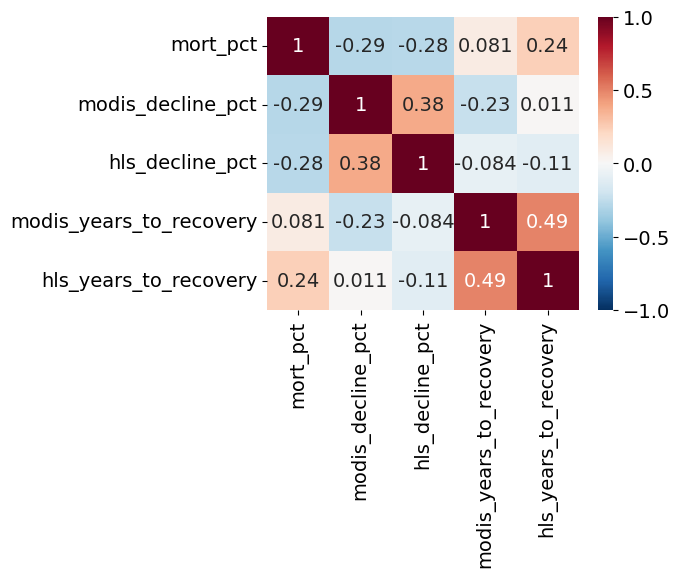

In [101]:
plt.figure(figsize=(7,6))

sns.heatmap(
    corr,
    annot=True,
    cmap='RdBu_r',
    vmin=-1,
    vmax=1
)

plt.tight_layout()

plt.savefig(
    '/content/drive/MyDrive/Figure6_Correlation_matrix.png',
    dpi=300
)

plt.show()

###Compute mortality correlations
once all site metrics table exists

In [51]:
from scipy.stats import pearsonr
from scipy.stats import spearmanr


for MODIS

In [52]:
r_modis, p_modis = pearsonr(
    results_df['mort_pct'],
    abs(results_df['modis_decline_pct'])
)

for HLS

In [53]:
r_hls, p_hls = pearsonr(
    results_df['mort_pct'],
    abs(results_df['hls_decline_pct'])
)


Spearman

In [54]:
rho_modis, _ = spearmanr(
    results_df['mort_pct'],
    abs(results_df['modis_decline_pct'])
)

rho_hls, _ = spearmanr(
    results_df['mort_pct'],
    abs(results_df['hls_decline_pct'])
)

then print

In [55]:
print(
    'MODIS',
    r_modis,
    rho_modis
)

print(
    'HLS',
    r_hls,
    rho_hls
)

MODIS 0.29161498014686354 0.18903237790264932
HLS 0.22652384503932946 0.4075916903722734


###We now want to create scatterplots of mortality % v NDVI_decline

Load the metrics table

In [56]:
import pandas as pd

df = pd.read_csv(
    '/content/drive/MyDrive/all_site_metrics_v2_FINAL.csv'
)

df.head()

,plot_id,mort_year,mort_pct,modis_pre_mean,modis_post_min,modis_decline_pct,modis_recovery_year,modis_years_to_recovery,hls_pre_mean,hls_post_min,hls_decline_pct,hls_recovery_year,hls_years_to_recovery
0,Wald_mort,2020,63.0,0.827772,0.777733,-6.045010,2024.0,4.0,0.839881,0.764204,-9.010419,2023.0,3.0
1,Wald_control,2020,10.0,0.808356,0.782904,-3.148588,2021.0,1.0,0.836102,0.815176,-2.502824,2021.0,1.0
2,Harz_mort,2019,80.0,0.853973,0.506657,-40.670543,NaN,NaN,0.848945,0.558385,-34.226007,NaN,NaN
3,Harz_control,2019,0.0,0.849212,0.718524,-15.389398,NaN,NaN,0.857912,0.703490,-17.999719,NaN,NaN
4,Bav_mort,2020,87.0,0.838864,0.747426,-10.900178,2021.0,1.0,0.830775,0.755605,-9.048132,NaN,NaN


####Create the HLS correlation scatterplot
Observed mortality (%) vs HLS NDVI decline (%)

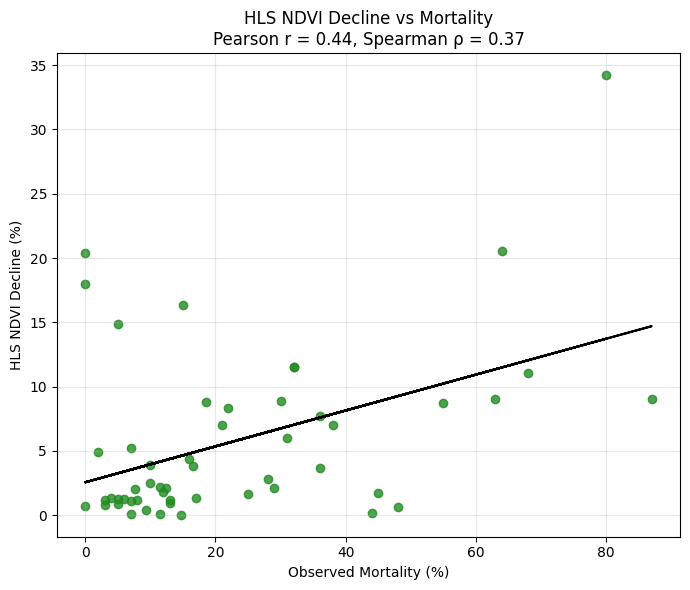

In [57]:
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from scipy.stats import spearmanr

x = df['mort_pct']

# Use absolute decline
y = abs(df['hls_decline_pct'])

r, p = pearsonr(x, y)
rho, p_s = spearmanr(x, y)

plt.figure(figsize=(7,6))

plt.scatter(
    x,
    y,
    color='forestgreen',
    alpha=0.8
)

m, b = np.polyfit(x, y, 1)

plt.plot(
    x,
    m*x + b,
    color='black'
)

plt.xlabel('Observed Mortality (%)')
plt.ylabel('HLS NDVI Decline (%)')

plt.title(
    f'HLS NDVI Decline vs Mortality\n'
    f'Pearson r = {r:.2f}, Spearman ρ = {rho:.2f}'
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    'HLS_Mortality_Scatter.png',
    dpi=300
)

plt.show()

####MODIS scatterplot

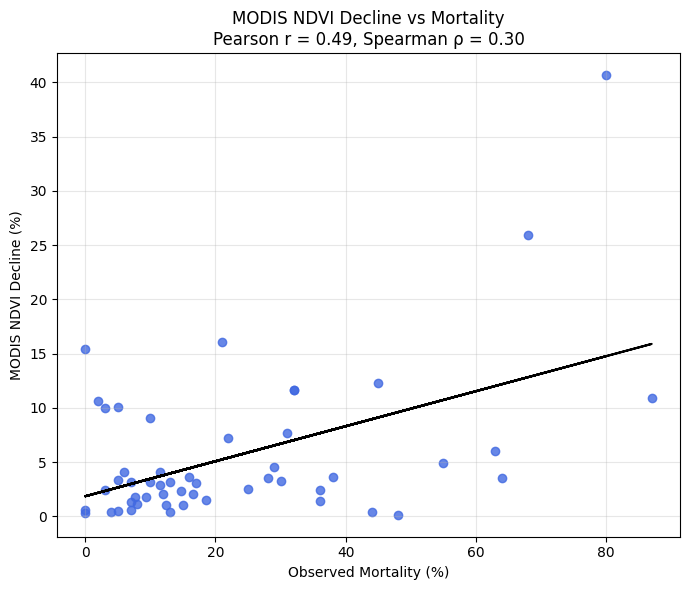

In [58]:
x = df['mort_pct']

y = abs(df['modis_decline_pct'])

r, p = pearsonr(x, y)
rho, p_s = spearmanr(x, y)

plt.figure(figsize=(7,6))

plt.scatter(
    x,
    y,
    color='royalblue',
    alpha=0.8
)

m, b = np.polyfit(x, y, 1)

plt.plot(
    x,
    m*x + b,
    color='black'
)

plt.xlabel('Observed Mortality (%)')
plt.ylabel('MODIS NDVI Decline (%)')

plt.title(
    f'MODIS NDVI Decline vs Mortality\n'
    f'Pearson r = {r:.2f}, Spearman ρ = {rho:.2f}'
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    'MODIS_Mortality_Scatter.png',
    dpi=300
)

plt.show()

####Combined scatterplot
to make comparison easier

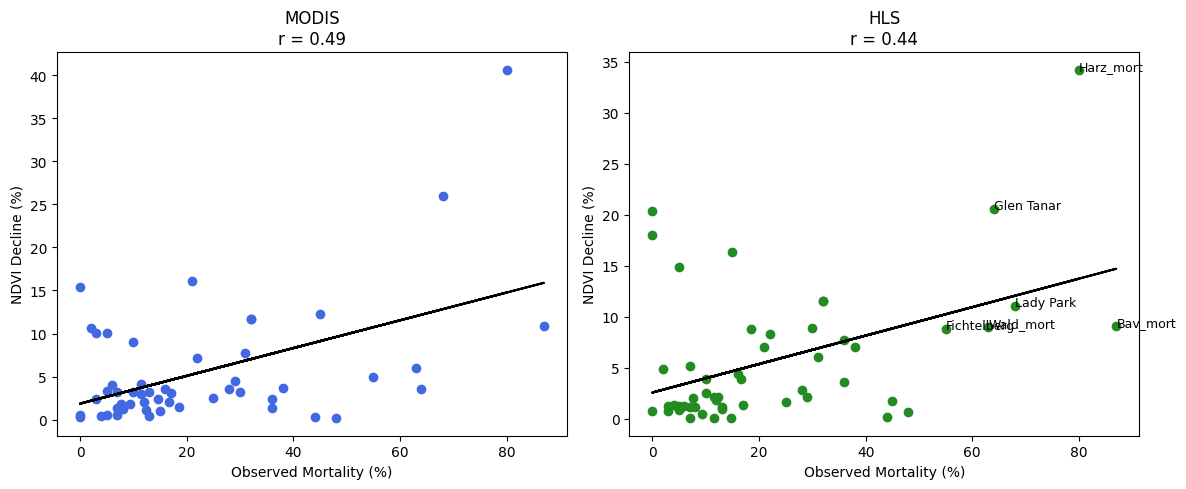

In [59]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12,5)
)

#label the strongest sites
for _, row in df.iterrows():

    if row['mort_pct'] > 50:

        plt.annotate(
            row['plot_id'],
            (
                row['mort_pct'],
                abs(row['hls_decline_pct'])
            ),
            fontsize=9
        )
# MODIS
x = df['mort_pct']
y = abs(df['modis_decline_pct'])

r_m, _ = pearsonr(x, y)

axes[0].scatter(
    x,
    y,
    color='royalblue'
)

m, b = np.polyfit(x, y, 1)

axes[0].plot(
    x,
    m*x+b,
    'k-'
)

axes[0].set_title(
    f'MODIS\nr = {r_m:.2f}'
)

axes[0].set_xlabel(
    'Observed Mortality (%)'
)

axes[0].set_ylabel(
    'NDVI Decline (%)'
)


# HLS
y = abs(df['hls_decline_pct'])

r_h, _ = pearsonr(x, y)

axes[1].scatter(
    x,
    y,
    color='forestgreen'
)

m, b = np.polyfit(x, y, 1)

axes[1].plot(
    x,
    m*x+b,
    'k-'
)

axes[1].set_title(
    f'HLS\nr = {r_h:.2f}'
)

axes[1].set_xlabel(
    'Observed Mortality (%)'
)

axes[1].set_ylabel(
    'NDVI Decline (%)'
)



plt.tight_layout()

plt.savefig(
    'MODIS_vs_HLS_Mortality.png',
    dpi=300
)

plt.show()

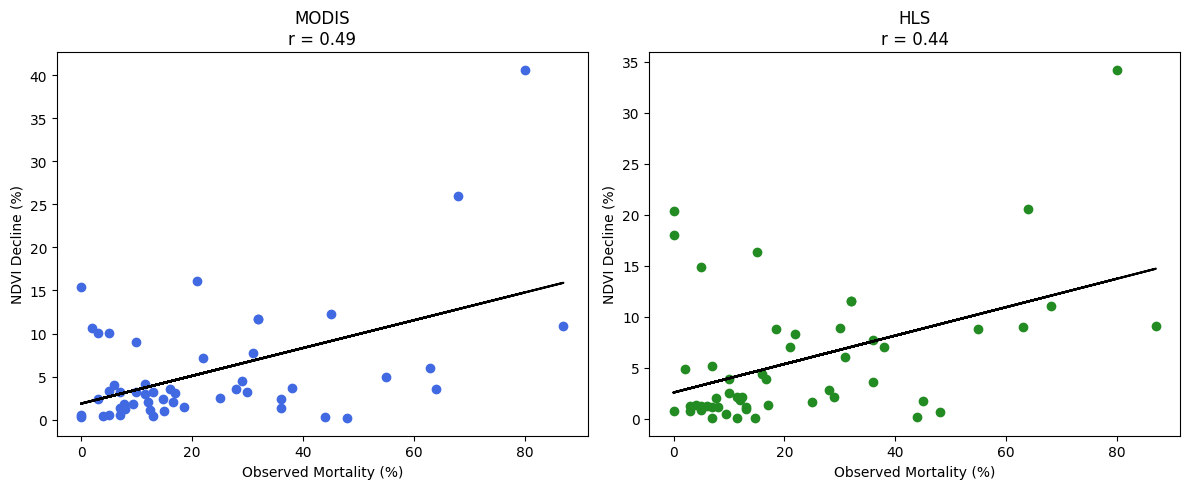

In [60]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12,5)
)

# MODIS
x = df['mort_pct']
y = abs(df['modis_decline_pct'])

r_m, _ = pearsonr(x, y)

axes[0].scatter(
    x,
    y,
    color='royalblue'
)

m, b = np.polyfit(x, y, 1)

axes[0].plot(
    x,
    m*x+b,
    'k-'
)

axes[0].set_title(
    f'MODIS\nr = {r_m:.2f}'
)

axes[0].set_xlabel(
    'Observed Mortality (%)'
)

axes[0].set_ylabel(
    'NDVI Decline (%)'
)


# HLS
y = abs(df['hls_decline_pct'])

r_h, _ = pearsonr(x, y)

axes[1].scatter(
    x,
    y,
    color='forestgreen'
)

m, b = np.polyfit(x, y, 1)

axes[1].plot(
    x,
    m*x+b,
    'k-'
)

axes[1].set_title(
    f'HLS\nr = {r_h:.2f}'
)

axes[1].set_xlabel(
    'Observed Mortality (%)'
)

axes[1].set_ylabel(
    'NDVI Decline (%)'
)



plt.tight_layout()

plt.savefig(
    'MODIS_vs_HLS_Mortality.png',
    dpi=300
)

plt.show()

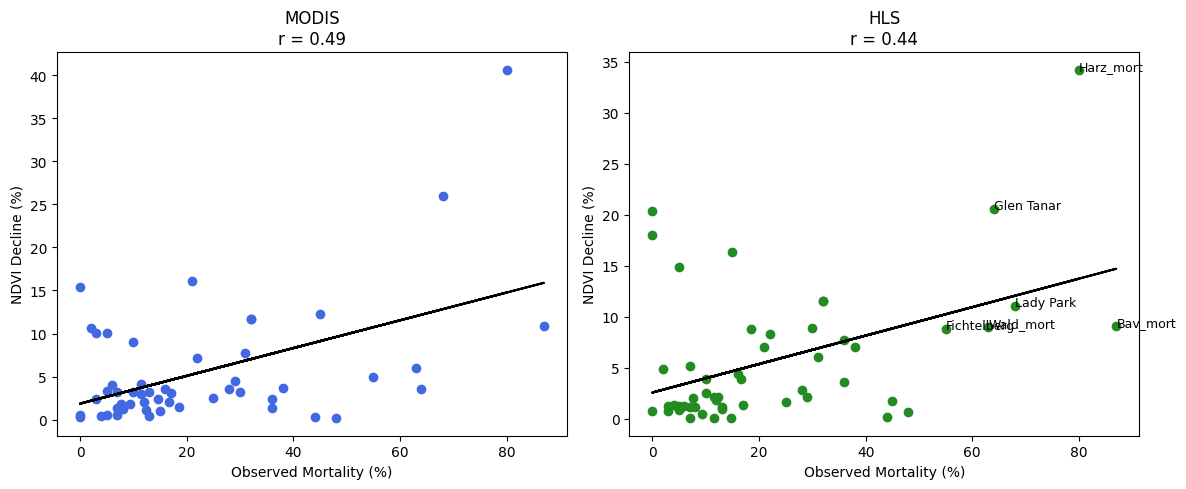

In [61]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12,5)
)

# MODIS
x = df['mort_pct']
y = abs(df['modis_decline_pct'])

r_m, _ = pearsonr(x, y)

axes[0].scatter(
    x,
    y,
    color='royalblue'
)

m, b = np.polyfit(x, y, 1)

axes[0].plot(
    x,
    m*x+b,
    'k-'
)

axes[0].set_title(
    f'MODIS\nr = {r_m:.2f}'
)

axes[0].set_xlabel(
    'Observed Mortality (%)'
)

axes[0].set_ylabel(
    'NDVI Decline (%)'
)


# HLS
y = abs(df['hls_decline_pct'])

r_h, _ = pearsonr(x, y)

axes[1].scatter(
    x,
    y,
    color='forestgreen'
)

m, b = np.polyfit(x, y, 1)

axes[1].plot(
    x,
    m*x+b,
    'k-'
)

axes[1].set_title(
    f'HLS\nr = {r_h:.2f}'
)

axes[1].set_xlabel(
    'Observed Mortality (%)'
)

axes[1].set_ylabel(
    'NDVI Decline (%)'
)

#label the strongest sites
for _, row in df.iterrows():

    if row['mort_pct'] > 50:

        plt.annotate(
            row['plot_id'],
            (
                row['mort_pct'],
                abs(row['hls_decline_pct'])
            ),
            fontsize=9
        )

plt.tight_layout()

plt.savefig(
    'MODIS_vs_HLS_Mortality.png',
    dpi=300
)

plt.show()

###Does HLS capture mortality better than MODIS? Create a new figure to test this out

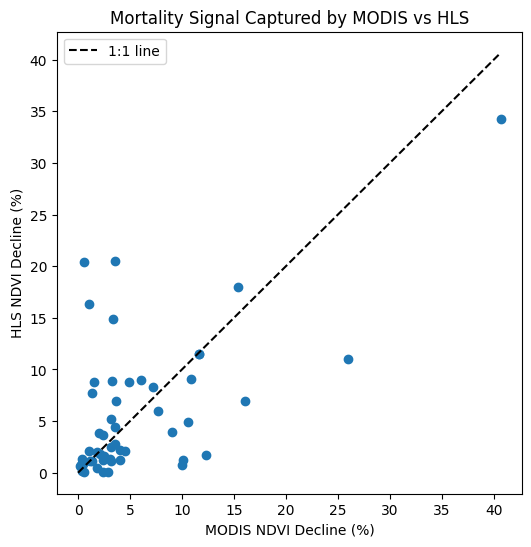

In [62]:
plt.figure(figsize=(6,6))

plt.scatter(
    abs(df['modis_decline_pct']),
    abs(df['hls_decline_pct'])
)

max_val = max(
    abs(df['modis_decline_pct']).max(),
    abs(df['hls_decline_pct']).max()
)

plt.plot(
    [0,max_val],
    [0,max_val],
    'k--',
    label='1:1 line'
)

plt.xlabel('MODIS NDVI Decline (%)')
plt.ylabel('HLS NDVI Decline (%)')

plt.legend()

plt.title(
    'Mortality Signal Captured by MODIS vs HLS'
)

plt.show()

Better code

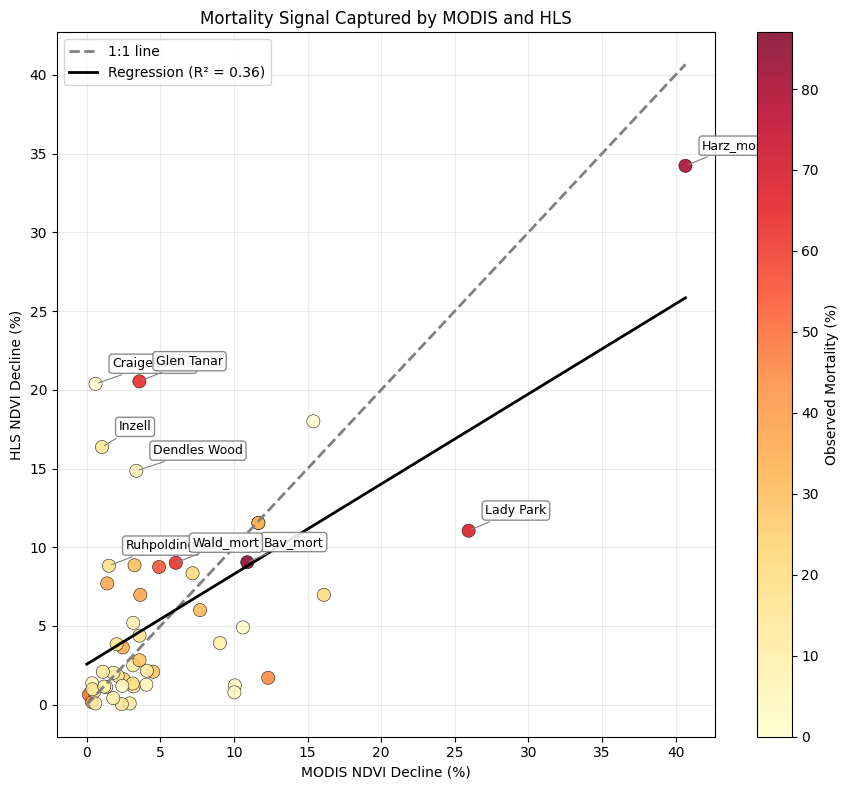

In [63]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

# -----------------------------
# Data
# -----------------------------

x = abs(df['modis_decline_pct'])
y = abs(df['hls_decline_pct'])

# -----------------------------
# Regression
# -----------------------------

reg = linregress(x, y)

r2 = reg.rvalue**2

max_val = max(
    x.max(),
    y.max()
)

# -----------------------------
# Plot
# -----------------------------

fig, ax = plt.subplots(
    figsize=(9,8)
)

sc = ax.scatter(
    x,
    y,
    c=df['mort_pct'],
    cmap='YlOrRd',
    s=90,
    edgecolor='black',
    linewidth=0.4,
    alpha=0.85
)

# 1:1 line

ax.plot(
    [0,max_val],
    [0,max_val],
    '--',
    color='grey',
    linewidth=2,
    label='1:1 line'
)

# regression line

xline = np.linspace(
    0,
    max_val,
    100
)

ax.plot(
    xline,
    reg.slope*xline + reg.intercept,
    color='black',
    linewidth=2,
    label=f'Regression (R² = {r2:.2f})'
)

# -----------------------------
# Select sites to label
# -----------------------------

df['difference'] = (
    abs(df['hls_decline_pct'])
    -
    abs(df['modis_decline_pct'])
)

# largest HLS outliers
outliers = df.nlargest(
    5,
    'difference'
)

# highest mortality sites
high_mort = df.nlargest(
    5,
    'mort_pct'
)

label_df = (
    pd.concat([outliers, high_mort])
      .drop_duplicates('plot_id')
)

# -----------------------------
# Labels
# -----------------------------

for _, row in label_df.iterrows():

    ax.annotate(
        row['plot_id'],
        xy=(
            abs(row['modis_decline_pct']),
            abs(row['hls_decline_pct'])
        ),
        xytext=(12,12),
        textcoords='offset points',
        fontsize=9,
        bbox=dict(
            boxstyle='round,pad=0.25',
            fc='white',
            ec='grey',
            alpha=0.9
        ),
        arrowprops=dict(
            arrowstyle='-',
            color='grey',
            lw=0.8
        )
    )

# -----------------------------
# Formatting
# -----------------------------

cbar = plt.colorbar(sc)
cbar.set_label(
    'Observed Mortality (%)'
)

ax.set_xlabel(
    'MODIS NDVI Decline (%)'
)

ax.set_ylabel(
    'HLS NDVI Decline (%)'
)

ax.set_title(
    'Mortality Signal Captured by MODIS and HLS'
)

ax.legend()

ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    'MODIS_HLS_Mortality_pct_1to1.png',
    dpi=300
)

plt.show()
